<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_9/dataset_pbl/praktikum_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**
## **Langkah 1 - Load Data**

In [ ]:
import pandas as pd

data = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')
data.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## **Langkah 2 - Eskplorasi Data**
Cek struktur data informasi deskriptif data

In [ ]:
# Tangani nilai kosong pada Sleep Disorder jika terbaca sebagai NaN
data['Sleep Disorder'] = data['Sleep Disorder'].fillna('None')

data.info()
display(data.describe())
data['Sleep Disorder'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           374 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


,count
Sleep Disorder,
None,219
Sleep Apnea,78
Insomnia,77


## **Langkah 3 - Visualisasi Data**
Lakukan visualisasi data untuk mengetahui distribusi dan korelasi setiap fitur terhadap label.

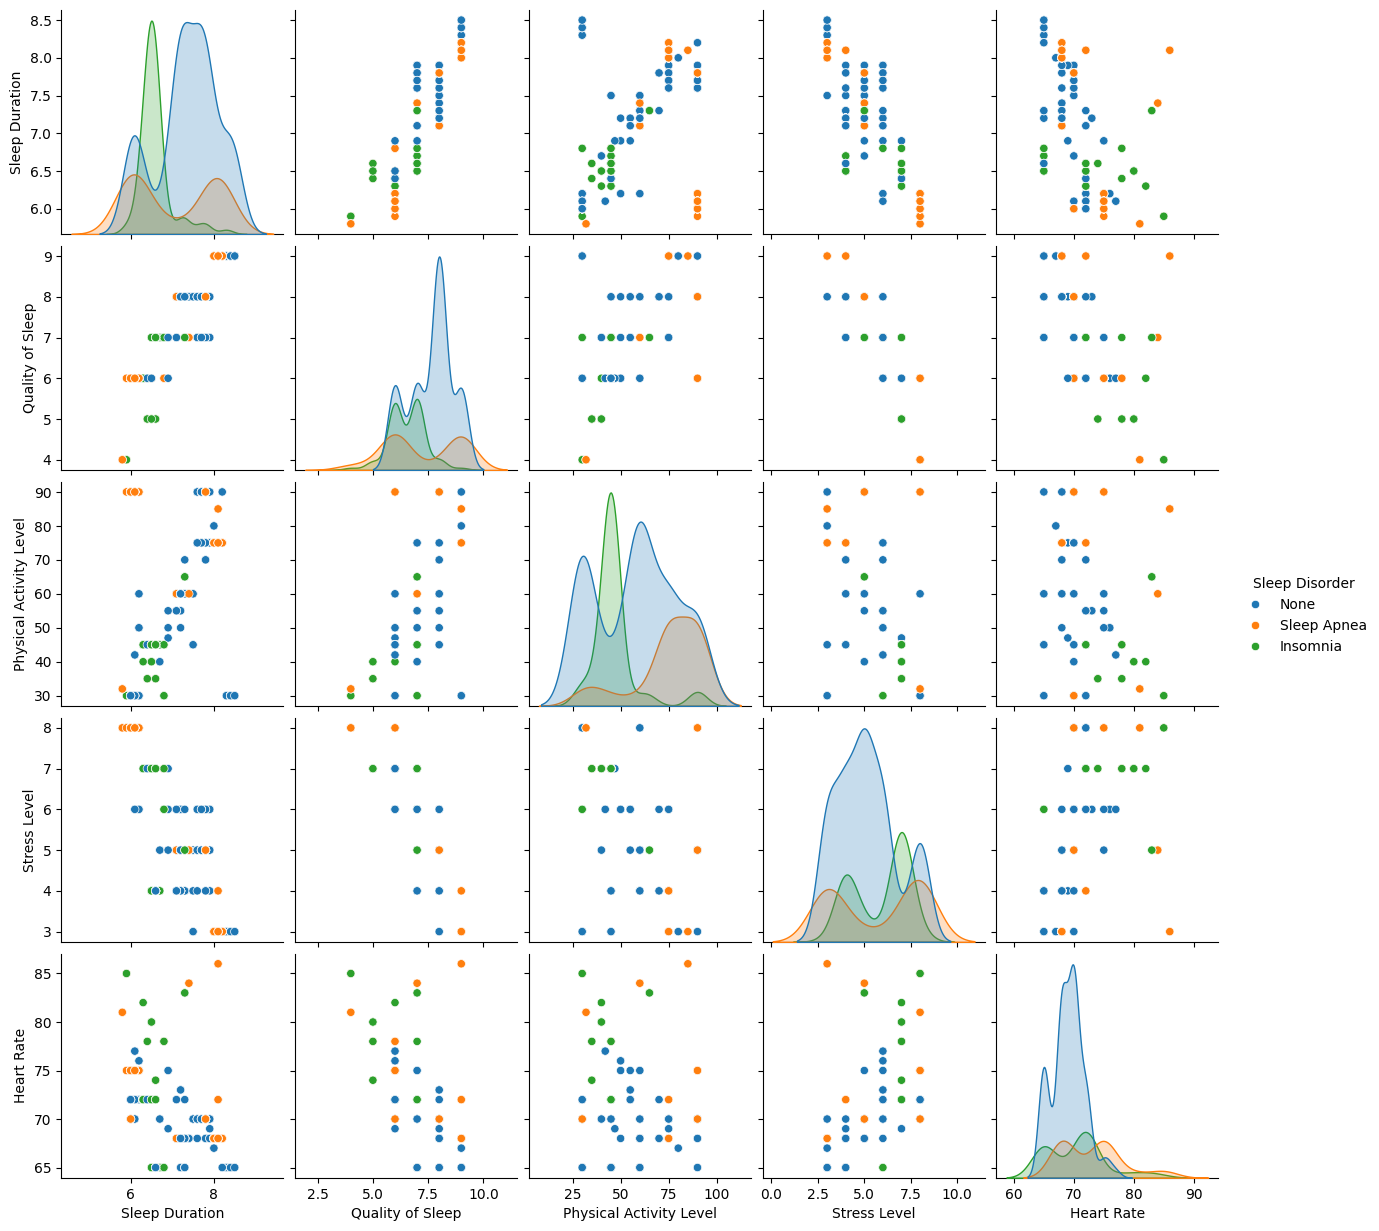

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fitur_visual = ['Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Sleep Disorder']
sns.pairplot(data[fitur_visual], hue='Sleep Disorder')
plt.show()

## **Langkah 4 - Preprocessing**
Pada tahap ini, kita akan memisahkan antara label dengan fitur yang akan digunakan. Selain itu, untuk alasan pembelajaran, kita akan melakukan standardisasi dari fitur yang akan digunakan.

Pada kasus Iris Dataset, seluruh fitur sudah dalam satuan yang sama yaitu cm.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Bersihkan kolom ID dan pecah Blood Pressure
df_clean = data.drop(columns=['Person ID'], errors='ignore').copy()
if 'Blood Pressure' in df_clean.columns:
    bp_split = df_clean['Blood Pressure'].str.split('/', expand=True)
    df_clean['Systolic_BP'] = pd.to_numeric(bp_split[0])
    df_clean['Diastolic_BP'] = pd.to_numeric(bp_split[1])
    df_clean = df_clean.drop(columns=['Blood Pressure'])

# Pisahkan fitur (X) dan target (y)
y = df_clean['Sleep Disorder']
X = pd.get_dummies(df_clean.drop(columns=['Sleep Disorder']), drop_first=True)

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## **Langkah 5 - Buat Model kNN**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

## **Langkah 6 - Evaluasi Model kNN**

Pada tahap ini kita akan melakukan evaluasi terhadap model kNN yang telah dibuat sebelumnya. Metrik utama yang akan digunakan adalah akurasi dan detail analisis menggunakan confusion metrics.

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 0.8672566371681416
Confusion Matrix:
 [[19  4  1]
 [ 2 60  0]
 [ 6  2 19]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

    Insomnia       0.70      0.79      0.75        24
        None       0.91      0.97      0.94        62
 Sleep Apnea       0.95      0.70      0.81        27

    accuracy                           0.87       113
   macro avg       0.85      0.82      0.83       113
weighted avg       0.88      0.87      0.87       113



Dapat dilihat bahwa model dapat bekerja dengan performa sempurna pada data testing. Namun apakah memang nilai k adalah nilai yang terbaik? Selanjutnya kita akan mengevaluasi setiap nilai k.

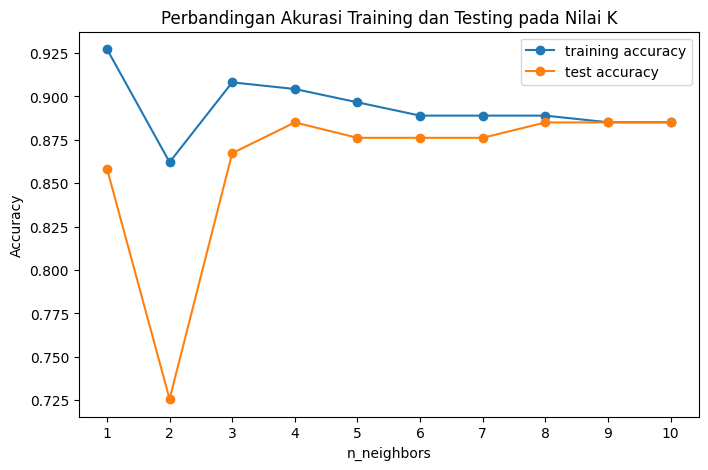

In [ ]:
training_accuracy = []
test_accuracy = []
neighbors_settings = range(1, 11)

for n_neighbors in neighbors_settings:
    clf = KNeighborsClassifier(n_neighbors=n_neighbors)
    clf.fit(X_train, y_train)
    training_accuracy.append(clf.score(X_train, y_train))
    test_accuracy.append(clf.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(neighbors_settings, training_accuracy, marker='o', label="training accuracy")
plt.plot(neighbors_settings, test_accuracy, marker='o', label="test accuracy")
plt.title('Perbandingan Akurasi Training dan Testing pada Nilai K')
plt.ylabel("Accuracy")
plt.xlabel("n_neighbors")
plt.xticks(neighbors_settings)
plt.legend()
plt.show()

Dapat dilihat bahwa performa data testing menghasilkan akurasi sebesar **86,73%** pada **k = 3**, diikuti oleh fluktuasi akurasi pada nilai **k** lainnya. Meskipun demikian, perlu dicatat bahwa algoritma kNN tidak menyimpan bobot hasil pelatihan (*lazy learner*), melainkan melakukan klasifikasi secara langsung berdasarkan jarak terhadap sejumlah tetangga terdekat. Oleh karena itu, performa pengujian perlu dibandingkan dengan akurasi data training untuk melihat keseimbangan model dan menghindari *overfitting*. Gambar di bawah ini merupakan perbandingan performa akurasi antara data training dan data testing pada berbagai nilai **k**.

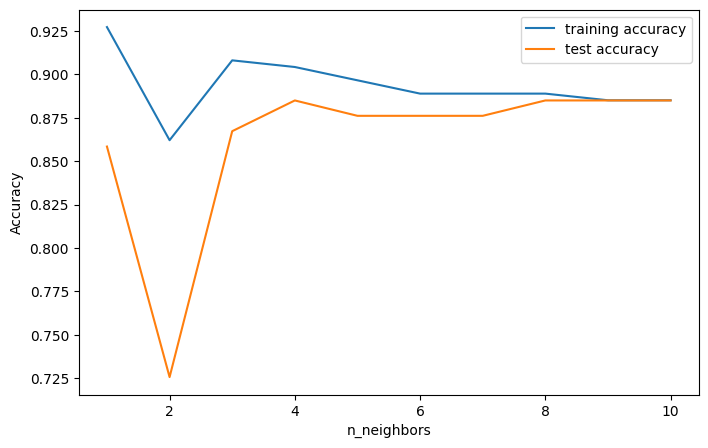

In [ ]:
# 1. Load Data
data = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')
data['Sleep Disorder'] = data['Sleep Disorder'].fillna('None')

df_clean = data.drop(columns=['Person ID'], errors='ignore').copy()
if 'Blood Pressure' in df_clean.columns:
    bp_split = df_clean['Blood Pressure'].str.split('/', expand=True)
    df_clean['Systolic_BP'] = pd.to_numeric(bp_split[0])
    df_clean['Diastolic_BP'] = pd.to_numeric(bp_split[1])
    df_clean = df_clean.drop(columns=['Blood Pressure'])

y = df_clean['Sleep Disorder']
X = pd.get_dummies(df_clean.drop(columns=['Sleep Disorder']), drop_first=True)

# 2. Split Data (Tanpa stratify, persis seperti Langkah 4 modul)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 3. Standardisasi
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

training_accuracy = []
test_accuracy = []

# 4. Pengujian Nilai K (1 - 10)
neighbors_settings = range(1, 11)

for n_neighbors in neighbors_settings:
    clf = KNeighborsClassifier(n_neighbors=n_neighbors)
    clf.fit(X_train_scaled, y_train)

    # Simpan akurasi training & testing
    training_accuracy.append(clf.score(X_train_scaled, y_train))
    test_accuracy.append(clf.score(X_test_scaled, y_test))

# 5. Visualisasi
plt.figure(figsize=(8, 5))
plt.plot(neighbors_settings, training_accuracy, label="training accuracy")
plt.plot(neighbors_settings, test_accuracy, label="test accuracy")
plt.ylabel("Accuracy")
plt.xlabel("n_neighbors")
plt.legend()
plt.show()